In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_recall_curve,
    roc_curve,
    roc_auc_score
)

import statsmodels.api as sm


In [2]:
#En primer lugar, importamos los conjuntos x_train , x_test , y_test y_train conseguidos durante el preprocesamiento.ipynb
# x cuenta con las variables predictoras y e y con la variable a predecir (impago) 
#hemos usado estos conjuntos ya que están ya preparados para entrenar y evaluar el  modelo, ya que de lo contrario tendríamos que repetir todo el procespo previo


base_path = Path.cwd()

X_train = pd.read_csv(base_path / "X_train_impago.csv")
X_test = pd.read_csv(base_path / "X_test_impago.csv")

y_train = pd.read_csv(base_path / "y_train_impago.csv").squeeze("columns")
y_test = pd.read_csv(base_path / "y_test_impago.csv").squeeze("columns")

In [3]:
#comprobamos la distribucion de impago, para saber cómo se distribuye el dataset(tanto en train como en test) con el objetivo de conocer si ambas clases tienen una presencia similar
#  Cómo se puede observar, el dataset está bastante desbalanceado, teniendo un 84,4% de no impago y un 11,5 % de impago
#una vez sabido esto,lo cual nos ayudará a la hora de interpretar las métricas del modelo, podemos comenzar a entrenar el modelo

 
print("\nPorcentaje de observaciones por clase en train:")
print(y_train.value_counts(normalize=True) * 100)

print("\nPorcentaje de observaciones por clase en test:")
print(y_test.value_counts(normalize=True) * 100)



Porcentaje de observaciones por clase en train:
Impago
0    88.447976
1    11.552024
Name: proportion, dtype: float64

Porcentaje de observaciones por clase en test:
Impago
0    88.449789
1    11.550211
Name: proportion, dtype: float64


In [4]:
#también analizaremos la correlación entre la variable objetivo y las variables predictoras 
#saber la relación lineal que tiene cada variable con el impago nos servirá como primer análisis antes de hacer la regresión

# Analizamos la correlación entre la variable objetivo Impago y las variables predictoras.
# Realizamos este análisis para conocer la relación lineal que presenta cada variable
# con el impago y observar cuáles muestran una mayor asociación positiva o negativa.
# Esto nos sirve como un primer análisis de la relación entre las variables antes de
# entrenar la regresión logística.

datos_correlacion = X_train.copy()
datos_correlacion["Impago"] = y_train.values

correlaciones = (
    datos_correlacion
    .corr()["Impago"]
    .drop("Impago")
    .sort_values(ascending=False)
)

print(correlaciones)

Ratio_Interes                   0.126984
Estado_Civil_Soltero            0.105324
Estudios_Grado Universitario    0.022679
Posesion_Hipoteca_1.0           0.009151
Estudios_Máster                 0.003939
Num_Creditos                    0.000268
Duracion                       -0.006971
Prima                          -0.018751
Ratio_Deuda_Ingresos           -0.024650
Estudios_Escolar               -0.028209
Scoring_Crediticio             -0.041950
Monto_Inicial                  -0.050373
Estado_Civil_Divorciado        -0.055359
Ingresos                       -0.084079
Meses_Empleo                   -0.162833
Edad                           -0.167416
Name: Impago, dtype: float64


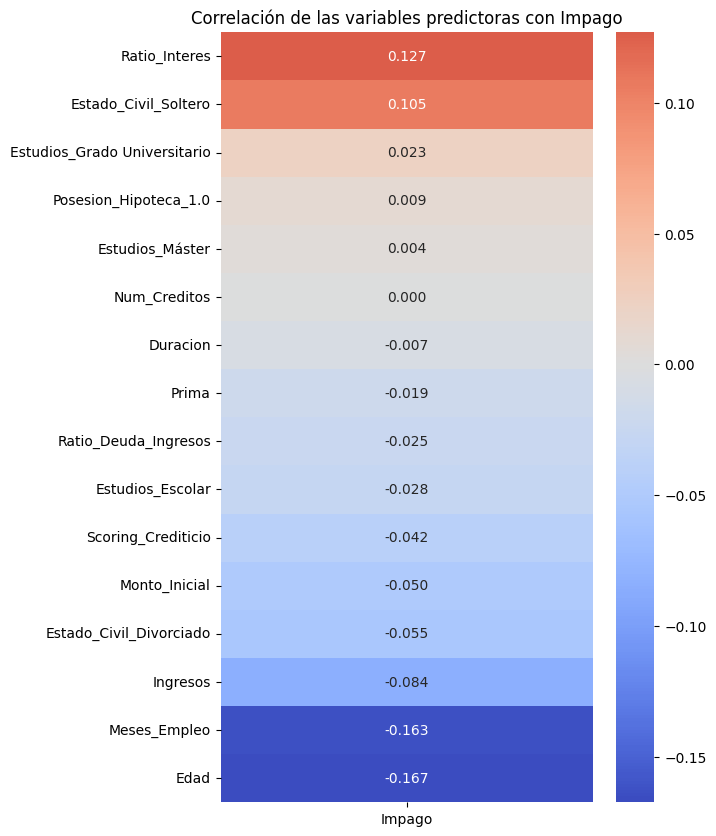

In [5]:
#vistos los resultados podemos obtener ciertas conclusiones así como que existe cierta correlación positiva con ciertas variables , así como el ratio de interés o el estado civil de la persona, por lo que a medida de que esa variable aumente , tiende a aumentar el impago.
#por otro lado, también existe cierta correlación negativa con variables como la edad o los meses de empleo, por lo que a medida que aumenta esa variable el impago tiende a disminuir
#visualizamos los resultados con un gráfico
# Representamos gráficamente las correlaciones para facilitar su interpretación.
import seaborn as sns
import matplotlib.pyplot as plt

correlaciones = correlaciones.sort_values(ascending=False).to_frame(name="Impago")

# Mapa de calor
plt.figure(figsize=(6, 10))

sns.heatmap(
    correlaciones,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".3f"
)

plt.title("Correlación de las variables predictoras con Impago")
plt.show()

In [6]:
#una vez los datos están listos, usaremos sklearn para crear y entrenar el modelo
#para estimare la probabilidad de impago, usaremos la regresión logística, ya que la variable impago es binaria(0=no impago 1= impoago)
#y este modelo permite estimar la probabilidad de pertenecer a una o a otra clase
#usaremos fit para que a partir de x_train y de y_train el modelo aprenda la relación entre las variables que se usan para predecir y entre la probabilidad de impago
modelo_log_sklearn = LogisticRegression()

modelo_log_sklearn.fit(X_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [7]:
#una vez entrenado el modelo, vamos a ver información del modelo, así como el intercepto y los coeficientes obtenidos
#gracias a esto podemos conocer qué variables aumentan o disminuyen la probabilidad de impago y conocer su relación con la variable objetivo
#también obtenemos el accuracy obtenida por el modelo sobre los datos del entrenamiento, lo cual nos sirve para conocer qué  proporción de train han sido clasificadaas adecuadamente 
#aun así , como hemos visto antes, existe un gran desbalance entre el impago y el no impago,por lo que el acuraccy no será sufuiciente para saber si el modelo es adecuado y usaremos metricas como el recall , precision o f1-score



print("\nIntercepto:")
print(modelo_log_sklearn.intercept_)

coeficientes = pd.DataFrame({
    "Variable": X_train.columns,
    "Coeficiente": modelo_log_sklearn.coef_.flatten()
})

print("\nCoeficientes:")
print(coeficientes)


print(
    "\nAccuracy de entrenamiento:",
    modelo_log_sklearn.score(X_train, y_train))


Intercepto:
[-2.33601145]

Coeficientes:
                        Variable  Coeficiente
0                   Meses_Empleo    -0.269188
1                  Ratio_Interes     0.411211
2                          Prima     0.005377
3                   Num_Creditos    -0.000396
4             Scoring_Crediticio    -0.121507
5                       Duracion    -0.023597
6                  Monto_Inicial    -0.023371
7                           Edad    -0.341578
8           Ratio_Deuda_Ingresos    -0.053486
9                       Ingresos     0.031602
10              Estudios_Escolar     0.151676
11  Estudios_Grado Universitario     0.078845
12               Estudios_Máster     0.013495
13       Estado_Civil_Divorciado    -0.019647
14          Estado_Civil_Soltero     0.007270
15         Posesion_Hipoteca_1.0     0.048691

Accuracy de entrenamiento: 0.8843985115130243


Realizamos predicciones probabilísticas:

- Con .predict_proba() se obtiene, para cada observación, la probabilidad predicha de pertenecer a cada una de las dos clases.

- Con .predict() se obtiene, para cada observación, la clasificación predicha por el modelo. Esta clasificación se corresponde con la clase con mayor probabilidad.

In [8]:
#una vez entrenado el modelo, lo utilizamos para conocer la probabilidad de que cada observación de test pertenezca a pago o a impago
#para ello usaremos predict_proba,la cual da probabilidad predicha de pertenecer a cada una de las dos clases.
#gracias a esto podemos conocer el nivel de riesgo de impago de cada cliente
probabilidades = modelo_log_sklearn.predict_proba(X_test)

probabilidades = pd.DataFrame(
    probabilidades,
    columns=modelo_log_sklearn.classes_
)

print("\nPrimeras probabilidades:")
print(probabilidades.head())



Primeras probabilidades:
          0         1
0  0.925994  0.074006
1  0.780709  0.219291
2  0.922595  0.077405
3  0.864693  0.135307
4  0.847288  0.152712


In [9]:

# Nos quedamos con la probabilidad de Impago(1), ya que de esa forma obtenemos una probabilidad concreta de impago para cliente, lo cual será interesante para analizar su riesgo o clasificarlo posteriormente

prob_impago = probabilidades[1]

#tambiénm vamos a transformar las probabilidades en una clasificación de 0 a 1, poniendo un thresold de 0,5 es decir, aquellos usuarios con probabilifdad de impago inferior al 50% serán clasificados como no impago
#mientras que aquellos que tengan una probabilidad de impago igual o mayor que el 50% serán clasificados como impago
#gracias a esto luego podremos comparar las predicciones del modelo con los valores reañes de y_test 
clasificacion = np.where(prob_impago < 0.5, 0, 1)

print("Primeras clasificaciones:")
print(clasificacion[:10])

Primeras clasificaciones:
[0 0 0 0 0 0 0 0 0 0]


In [10]:
#también ajustamos la regresión logística usando statsmodels, ya que nos permite obtener información estadística más detallada sdobre el modelo(r2,std err...)
#ademas, podremnos conocer qué variables contribuyen a explicar el impago
# Statsmodels necesita que todas las variables sean numéricas
X_train_stats = X_train.astype(float)

# Añadir constante para calcular el intercepto
X_train_stats = sm.add_constant(X_train_stats, prepend=True)

modelo_log_statsm = sm.Logit(
    endog=y_train,
    exog=X_train_stats
)

modelo_log_statsm = modelo_log_statsm.fit()

print("\nResumen del modelo:")
print(modelo_log_statsm.summary())

Optimization terminated successfully.
         Current function value: 0.333540
         Iterations 7

Resumen del modelo:
                           Logit Regression Results                           
Dep. Variable:                 Impago   No. Observations:                61539
Model:                          Logit   Df Residuals:                    61522
Method:                           MLE   Df Model:                           16
Date:                Wed, 14 Oct 2026   Pseudo R-squ.:                 0.06807
Time:                        10:33:30   Log-Likelihood:                -20526.
converged:                       True   LL-Null:                       -22025.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                   coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------------
const                           -2.3346      0.071 

In [11]:
#calculamos el intervalos de confianza de los coeficientes(95% del modelo)
#gracias a esto conocemos el rango de valores dentro del cual se espera que esté el coeficiente de verdad de cada predictor

intervalos_ci = modelo_log_statsm.conf_int(alpha=0.05).rename(columns={0: "2.5%", 1: "97.5%"})

intervalos_ci

,2.5%,97.5%
const,-2.473328,-2.195849
Meses_Empleo,-0.389982,-0.153239
Ratio_Interes,0.385367,0.437352
Prima,-0.039777,0.050256
Num_Creditos,-0.025821,0.025019
Scoring_Crediticio,-0.148783,-0.094664
Duracion,-0.052315,0.005232
Monto_Inicial,-0.066773,0.021871
Edad,-0.446805,-0.227427
Ratio_Deuda_Ingresos,-0.093946,-0.014105


In [12]:
#creamos una tabla con los principales resultados de cada variable 
#metemos el coeficiente , el p-valor, y el intervalo de confianza del 95%
tabla= pd.DataFrame({
    "Variable": modelo_log_statsm.params.index,
    "Coeficiente": modelo_log_statsm.params.values,
    "p-valor": modelo_log_statsm.pvalues.values,
    "IC 2,5 %": modelo_log_statsm.conf_int()[0].values,
    "IC 97,5 %": modelo_log_statsm.conf_int()[1].values
})

tabla.head(15)

,Variable,Coeficiente,p-valor,"IC 2,5 %","IC 97,5 %"
0,const,-2.334588,1.542980e-238,-2.473328,-2.195849
1,Meses_Empleo,-0.271610,6.883584e-06,-0.389982,-0.153239
2,Ratio_Interes,0.411359,3.020168e-211,0.385367,0.437352
3,Prima,0.005240,8.195530e-01,-0.039777,0.050256
4,Num_Creditos,-0.000401,9.753240e-01,-0.025821,0.025019
5,Scoring_Crediticio,-0.121724,1.179455e-18,-0.148783,-0.094664
6,Duracion,-0.023542,1.088045e-01,-0.052315,0.005232
7,Monto_Inicial,-0.022451,3.208137e-01,-0.066773,0.021871
8,Edad,-0.337116,1.704555e-09,-0.446805,-0.227427
9,Ratio_Deuda_Ingresos,-0.054026,7.990363e-03,-0.093946,-0.014105


In [13]:
#también vamos a obtener las probabilidades de impago con el modelo de statsmodels, la cual no aplica regularización por defecto como scikit-learn

# Convertimos las predictoras a float para que no de error( como ya ha ocurrido)

X_test_statsm = X_test.astype(float)

# Añadimos el intercepto, igual que al entrenar.
X_test_statsm = sm.add_constant(X_test_statsm, has_constant="add")

# Ordenamos las columnas igual que en el modelo entrenado.
X_test_statsm = X_test_statsm[modelo_log_statsm.model.exog_names]

# Obtenemos las probabilidades de impago con Statsmodels.
probabilidades_statsm = modelo_log_statsm.predict(X_test_statsm)

probabilidades_statsm.head(4)

0    0.074039
1    0.219119
2    0.077307
3    0.135473
dtype: float64

In [14]:
# Hallamos la clasificación predicha estableciendo un umbral de probabilidad 0.5

clasificacion = np.where(probabilidades_statsm<0.5, 0, 1)
clasificacion[:4]

array([0, 0, 0, 0])

METRICAS DE RENDIMIENTO


In [15]:
# Accuracy / Aciertos: 
""" 
Mide la proporción de predicciones correctas sobre el total de observaciones evaluadas
"""

from sklearn.metrics import accuracy_score

acierto = accuracy_score(y_test, clasificacion)
error = 1 - acierto
print("Acierto:", round(acierto*100, 2), "%")
print("Error:", round(error*100, 2), "%")

Acierto: 88.43 %
Error: 11.57 %


In [16]:
# Precisión, Recall, f1-score
""" 
Precision: Cada vez que el modelo predijo una clase, acerto ese porcentaje
Recall: De todos los datos que eran de esa clase, detectó ese porcentaje
F1-score: El valor será alto si precisión y sensibilidad son similares, útil para comparar clasificadores.
"""



from sklearn.metrics import classification_report

print(classification_report(y_test, clasificacion))

              precision    recall  f1-score   support

           0       0.88      1.00      0.94     13608
           1       0.20      0.00      0.00      1777

    accuracy                           0.88     15385
   macro avg       0.54      0.50      0.47     15385
weighted avg       0.81      0.88      0.83     15385



[[13604     4]
 [ 1776     1]]


<Axes: >

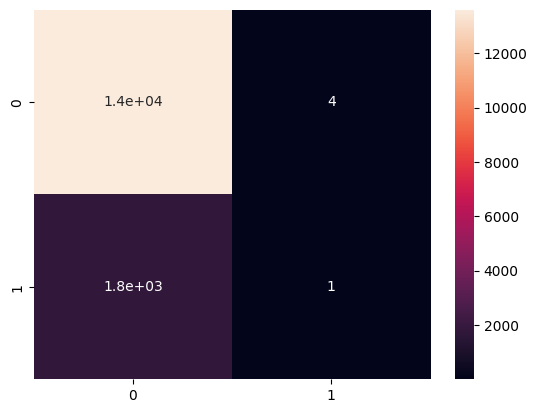

In [17]:
# hacemos la Matriz de confusión

from sklearn.metrics import confusion_matrix

c_matrix = confusion_matrix(y_test, clasificacion)
print(c_matrix)

sns.heatmap(c_matrix, annot=True)

In [18]:
from sklearn.metrics import precision_recall_curve

#sacamos la curva de precision/recall.

prec, rec, thresholds = precision_recall_curve(
    y_test, probabilidades_statsm
)

pd.DataFrame({
    "prec": prec[:-1],
    "rec": rec[:-1],
    "threshold": thresholds
}).iloc[80:100]

,prec,rec,threshold
80,0.115975,0.998875,0.017950
81,0.115983,0.998875,0.017955
82,0.115990,0.998875,0.017998
83,0.115998,0.998875,0.018012
84,0.116005,0.998875,0.018013
85,0.116013,0.998875,0.018076
86,0.116021,0.998875,0.018090
87,0.116028,0.998875,0.018112
88,0.116036,0.998875,0.018114
89,0.116043,0.998875,0.018207


Text(0.5, 1.0, 'PR Curve')

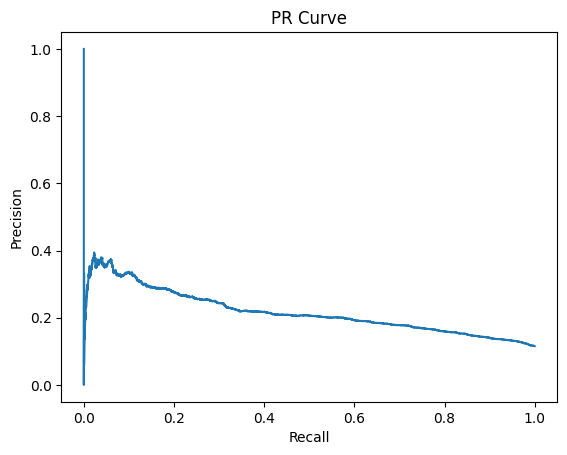

In [19]:
# Creamos la curva

plt.plot(rec, prec)

plt.xlabel("Recall")
plt.ylabel("Precision")

plt.title("PR Curve")

In [20]:
# Curva ROC: 

 
#- tpr (True Positive Rate / Sensibilidad / Recall): Porcentaje de casos positivos (1) reales que el modelo logra detectar
#- fpr (False Positive Rate / 1 - Especificidad): Porcentaje de casos negativos (0) reales que el modelo clasifica erróneamente como positivos.
# threshold: El umbral de probabilidad utilizado para obtener esa combinación específica de tpr y fpr.

from sklearn.metrics import roc_curve

# Seleccionamos únicamente la probabilidad de impago (clase 1).
probabilidades_impago = probabilidades.iloc[:, 1]

# Calculamos los puntos de la curva ROC.
fpr, tpr, threshold = roc_curve(y_test, probabilidades_impago)

pd.DataFrame({
    "tpr": tpr,
    "fpr": fpr,
    "threshold": threshold
})

,tpr,fpr,threshold
0,0.000000,0.000000,inf
1,0.000000,0.000073,0.552977
2,0.000000,0.000147,0.539107
3,0.000563,0.000147,0.536895
4,0.000563,0.001176,0.437714
...,...,...,...
3026,0.998875,0.996987,0.015952
3027,0.999437,0.996987,0.015932
3028,0.999437,0.998530,0.014770
3029,1.000000,0.998530,0.014744


Text(0.5, 1.0, 'Curva ROC')

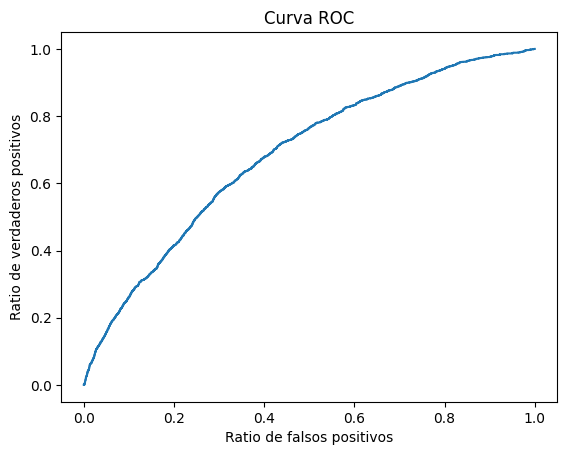

In [21]:
import matplotlib.pyplot as plt

plt.plot(fpr, tpr)

plt.xlabel("Ratio de falsos positivos")
plt.ylabel("Ratio de verdaderos positivos")
plt.title("Curva ROC")

OPTIMIZACIÓN DEL MODELO

In [ ]:
#Una vez construido y evaluado el modelo inicial, vamos a optimizarlo mediante distintos métodos, así como la regularización, la busqueda de hiperparametros y selección del umbral de clasificación

REGULARIZACIÓN

In [ ]:
#vamos a empezar con la regularización. para ello, probaremos los 3 tipos estudiados en clase(l1,l2 y elastic net) para posteriormente elegir el más óptimo, y finalmente elegir el umbral de decisión
#también vamos a probar distintos valores para C ,la cual controla la fuerza de regularización( el inverso de la fuerza de regulareizacion)

from sklearn.model_selection import GridSearchCV, StratifiedKFold



In [ ]:
#primero creamos una regresion logistica que servirá como base para gridsearch
#utilizamos solver=saga porque es compatible con las regularizaciones que vamos a probar, y max_iter para  que el modelo tenga suficiente iteraciones

modelo_cs=LogisticRegression(solver="saga",max_iter=5000)

#no añadimos cosas como la validacion cruzada ni las metricas , ya que eso lo implementaremos mediante gridsearch, ya que prueba varias configuracionmes y dice cuál es la más óptima

In [24]:
#ahora definimos distintos valores para c
#cuanto mayor sea la c, menor regularizacion habrá, mientras que sea menor , hab´ra más regularizaciom
#elegimos (-4,4,50) , es decir, # 50 valores de C entre 0.0001 y 10000, en escala logarítmica
cs=np.logspace(-4,4,50)
cs

array([1.00000000e-04, 1.45634848e-04, 2.12095089e-04, 3.08884360e-04,
       4.49843267e-04, 6.55128557e-04, 9.54095476e-04, 1.38949549e-03,
       2.02358965e-03, 2.94705170e-03, 4.29193426e-03, 6.25055193e-03,
       9.10298178e-03, 1.32571137e-02, 1.93069773e-02, 2.81176870e-02,
       4.09491506e-02, 5.96362332e-02, 8.68511374e-02, 1.26485522e-01,
       1.84206997e-01, 2.68269580e-01, 3.90693994e-01, 5.68986603e-01,
       8.28642773e-01, 1.20679264e+00, 1.75751062e+00, 2.55954792e+00,
       3.72759372e+00, 5.42867544e+00, 7.90604321e+00, 1.15139540e+01,
       1.67683294e+01, 2.44205309e+01, 3.55648031e+01, 5.17947468e+01,
       7.54312006e+01, 1.09854114e+02, 1.59985872e+02, 2.32995181e+02,
       3.39322177e+02, 4.94171336e+02, 7.19685673e+02, 1.04811313e+03,
       1.52641797e+03, 2.22299648e+03, 3.23745754e+03, 4.71486636e+03,
       6.86648845e+03, 1.00000000e+04])